In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-box-plot

**Figure 1: Response lengths of the base model and our RL-trained model on three math datasets.** Each box summarizes 60 responses; boxes span the quartiles with the median as a line, and whiskers reach 1.5× the interquartile range. RL training lengthens responses on every dataset, most on AIME, where the median grows from 873 to 1670 tokens (+797, 1.9×).

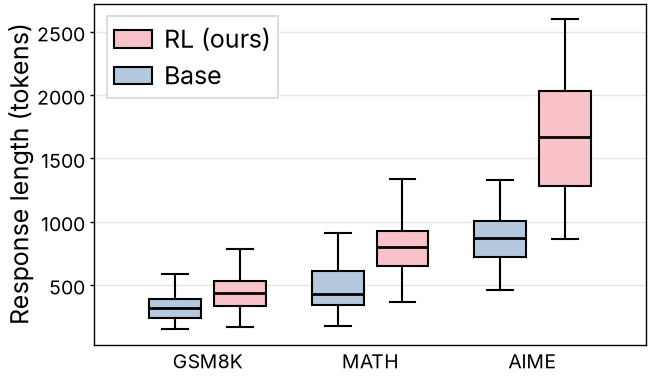

In [2]:
from matplotlib.patches import Patch

with open("../grouped-box-plot.json") as f:
    data = json.load(f)
datasets = data["datasets"]
series = {"Base": colors["series-1"], "RL (ours)": colors["ours"]}

fig, ax = plt.subplots(figsize=(3.25, 2))
x = np.arange(len(datasets))
width = 0.8 / len(series)
handles = []
for i, (name, color) in enumerate(series.items()):
    offset = (i - (len(series) - 1) / 2) * width
    for j, dataset in enumerate(datasets):
        box = ax.boxplot(data["lengths"][name][dataset], positions=[x[j] + offset], widths=0.8 * width, showfliers=False)
        box["boxes"][0].set_facecolor(lighten(color))
    handles.append(Patch(facecolor=lighten(color), edgecolor="black", linewidth=0.75, label=name))

ax.set_xticks(x, labels=datasets)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Response length (tokens)")
ax.legend(handles=handles[::-1], loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("grouped-box-plot.pdf")
fig.savefig("grouped-box-plot.png")
plt.show()